In [57]:
import numpy as np
from Bio.Seq import Seq

In [58]:
dna = Seq("CGATCGATCGAT")
print(dna)

CGATCGATCGAT


In [59]:
def GC_Counter(seq):
    gc =[]
    
    for x in seq:
        if x in "GC":
            gc.append(x)
    
    return len(gc) / len(seq) * 100

print(GC_Counter(dna))

50.0


In [60]:
gc = GC_Counter(dna)
at = 100 - gc
print(gc)
print(at)

50.0
50.0


In [61]:
from Bio.SeqUtils import GC
print(GC(dna))

50.0


In [62]:
import matplotlib.pyplot as plt

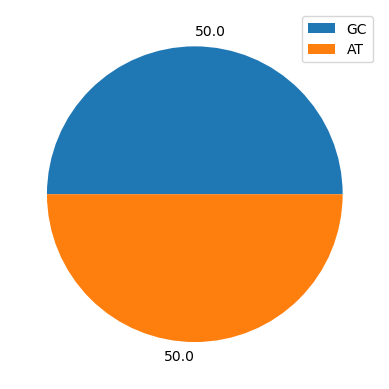

In [63]:
plt.pie(
    x = [gc, at],
    labels = [gc, at]
)
plt.legend(["GC", "AT"])
plt.show()

In [64]:
# Seq di bawah 14 basa -> Wallace
# Seq di atas 13 basa -> GC Composition
# 2 * (A + T) + 4 * (G + C)
# 64.9 + 41 * (G + C - 16.4) / (A + T + G + C)

def MeltingTemperature(seq):
    g = seq.count("G")
    c = seq.count("C")
    a = seq.count("A")
    t = seq.count("T")

    wallace = 2 * (a + t) + 4 * (g + c)
    gc_composition = 64.9 + 41 * (g + c - 16.4) / (a + t + g + c)
    
    if len(seq) < 14:
        return wallace
    else:
        return gc_composition

In [65]:
print(MeltingTemperature(dna))

36


In [66]:
dna2 = Seq("CGATCGATCGATCGAT")
print(MeltingTemperature(dna2))

43.375000000000014


In [67]:
from Bio.SeqUtils import MeltingTemp as mt

In [68]:
print(mt.Tm_Wallace(dna))
print(mt.Tm_Wallace(dna2))

36.0
48.0


In [69]:
print(mt.Tm_GC(dna))
print(mt.Tm_GC(dna2))

30.154892265415167
42.65489226541517


In [70]:
print(mt.Tm_NN(dna))
print(mt.Tm_NN(dna2))

32.71608193055266
44.57810923234808


In [71]:
from Bio.SeqUtils import molecular_weight as mw

In [72]:
print(mw(dna))
print(mw(dna2))

3725.3775
4961.1649


In [73]:
def split_nucleotide(seq, nucleotide):
    n = [x for x in seq if x in nucleotide]
    return "".join(n)

In [74]:
print(split_nucleotide(dna, "C"))
print(mw(split_nucleotide(dna, "C")))
print(mw(split_nucleotide(dna, "G")))
print(mw(split_nucleotide(dna, "A")))
print(mw(split_nucleotide(dna, "T")))

CCC
885.5606999999999
1005.633
957.6347999999998
930.5949
